# Örnek öğrenme oturumu ve çalışma önerileri

Doğrulama kümesinden, yeterli geçmiş uzunluğu ve sabit rastgele başlangıçla
seçilmiş bir öğrencinin ilk beş cevabı başlangıçtır. Sonraki 20 gerçek
kayıt yeniden oynatılır. Öğrenci, sonuç eğrisine göre seçilmemiştir.
Tahmin önce üretilir; gerçek cevap daha sonra geçmişe eklenir.

In [1]:
from pathlib import Path
import inspect
import json
import os
import subprocess
import sys
import numpy as np
import pandas as pd
from IPython.display import display, Image, Code

ROOT = Path.cwd().resolve()
if not (ROOT / "src/kt_project").exists():
    ROOT = ROOT.parent
assert (ROOT / "src/kt_project").exists(), "Defteri proje klasöründen açın."
sys.path.insert(0, str(ROOT / "src"))
os.environ.setdefault("CUDA_CACHE_PATH", str(ROOT / ".runtime/cuda"))

def read_json(name):
    return json.loads((ROOT / name).read_text(encoding="utf-8"))

def run_script(name):
    result = subprocess.run([sys.executable, str(ROOT / "scripts" / name)],
                            cwd=ROOT, capture_output=True, text=True,
                            encoding="utf-8", errors="replace")
    print(result.stdout)
    if result.returncode:
        print(result.stderr)
    result.check_returncode()

if not (ROOT / "outputs/patterns/behavior_model.joblib").exists():
    run_script("fit_behavior_patterns.py")
if not (ROOT / "outputs/replay/session.json").exists():
    run_script("run_student_replay.py")
metadata = read_json("outputs/patterns/metadata.json")
session = read_json("outputs/replay/session.json")
print("Proje klasörü:", ROOT)

Proje klasörü: C:\Users\unalm\OneDrive\Belgeler\ChatGPT\Prompt tuning for Knowledge tracing


## Cevaptan önce tahmin ve cevaptan sonra güncelleme

Model ağırlıkları, referans sorular ve öğrenilmiş gruplar sabittir.
Her cevap sonrası öğrenci geçmişi yenilenir. Aşağıdaki fonksiyon gerçek
akışı gösterir; kayıtlı çıktı bu fonksiyonla üretilmiştir.

def run_replay(root, store, tracer, bank, pattern_model, catalog, config, progress=None):
    names, inverse_questions = load_display_metadata(root)
    student = choose_replay_student(store, config)
    start, _ = store.spans[student]
    stop = start+config["replay_initial_history"]
    snapshot = snapshot_for(store, student, stop)
    tracked = active_skills(store, snapshot, 6, config["window_size"], bank)
    model_before = state_digest(cpu_state(tracer.model))
    pattern_before, bank_before = pattern_state_digest(pattern_model), bank.content_sha256()
    initial = current_state(store, snapshot, tracked, tracer, bank, pattern_model,
                            catalog, config, names, inverse_questions)
    started = datetime.now(ZoneInfo("Europe/Istanbul")).isoformat(timespec="milliseconds")
    events = []
    for step in range(1, config["replay_steps"]+1):
        target = snapshot.stop
        question = {"question": int(store.arrays["question"][target]),
                    "skills": store.arrays["skills"][target][store.arrays["skills"][target] > 0].tolist(),
                    "difficulty": float(store.arrays["difficulty"][target])}
        # Gerçek cevap burada henüz okunmaz; istek hiçbir cevap etiketi içermez.
        probability = float(tracer.predict_requests([(snapshot, question)], config["prediction_batch_size"])[0])
        actual = int(store.arrays["correct"][target])
        history_stop_before = snapshot.stop
        snapshot = snapshot_for(store, student, target+1)
        for skill in question["skills"]:
            if skill > 1 and bank.has_skill(skill) and skill not in tracked and len(tracked) < 6:
                tracked.append(skill)
        state = current_state(store, snapshot, tracked, tracer, bank, pattern_model,
                              catalog, config, names, inverse_questions)
        timestamp = datetime.now(ZoneInfo("Europe/Istanbul")).isoformat(timespec="milliseconds")
        event = {"step": step, "target_row_index": target, "history_stop_before": history_stop_before,
                 "source_order_id": int(store.arrays["order"][target]), "source_timestamp": None,
                 "display_timestamp": timestamp, "question": question["question"],
                 "original_problem_id": inverse_questions.get(question["question"]),
                 "predicted_before_response": probability, "observed_correct": actual, "after": state}
        events.append(event)
        if progress:
            progress(step, config["replay_steps"])
    integrity = {
        "model_weights_unchanged": model_before == state_digest(cpu_state(tracer.model)),
        "behavior_model_unchanged": pattern_before == pattern_state_digest(pattern_model),
        "reference_bank_unchanged": bank_before == bank.content_sha256(),
        "each_prediction_precedes_target_response": all(row["history_stop_before"] == row["target_row_index"] for row in events),
        "source_calendar_times_fabricated": False,
    }
    if not all(value for key, value in integrity.items() if key != "source_calendar_times_fabricated"):
        raise AssertionError("Oturum güvenilirlik kontrolü başarısız.")
    return {"student_alias": "Örnek öğrenci", "encoded_student": student,
            "source_split": "validation", "selection_uses_response_outcomes": False,
            "selection_rule": "fixed random seed among validation histories of sufficient length",
            "display_started_at": started, "source_calendar_timestamp_available": False,
            "initial": initial, "events": events, "integrity": integrity,
            "reference_bank_sha256": bank.source_sha256, "model_selection": tracer.selection,
            "note": "Mevcut geçmişin yeniden oynatımıdır; gerçek zamana yayılmış öğrenme kazanımı veya öneri etkisi ölçülmez."}

,Adım,Mevcut soru kimliği,Cevaptan önce tahmin %,Gerçek cevap (1 doğru),Son 20 cevapta doğru %,Cevaptan sonraki grup
0,1,85313,64.51,1,33.33,0
1,2,84733,72.80,1,42.86,0
2,3,53701,55.59,1,50.00,0
3,4,89713,70.33,0,44.44,0
4,5,89665,47.82,0,40.00,1
5,6,89663,60.77,1,45.45,0
6,7,89721,63.88,1,50.00,0
7,8,89709,63.79,0,46.15,0
8,9,89752,44.89,0,42.86,1
9,10,89710,55.98,0,40.00,1


Grup geçiş sayısı: 6


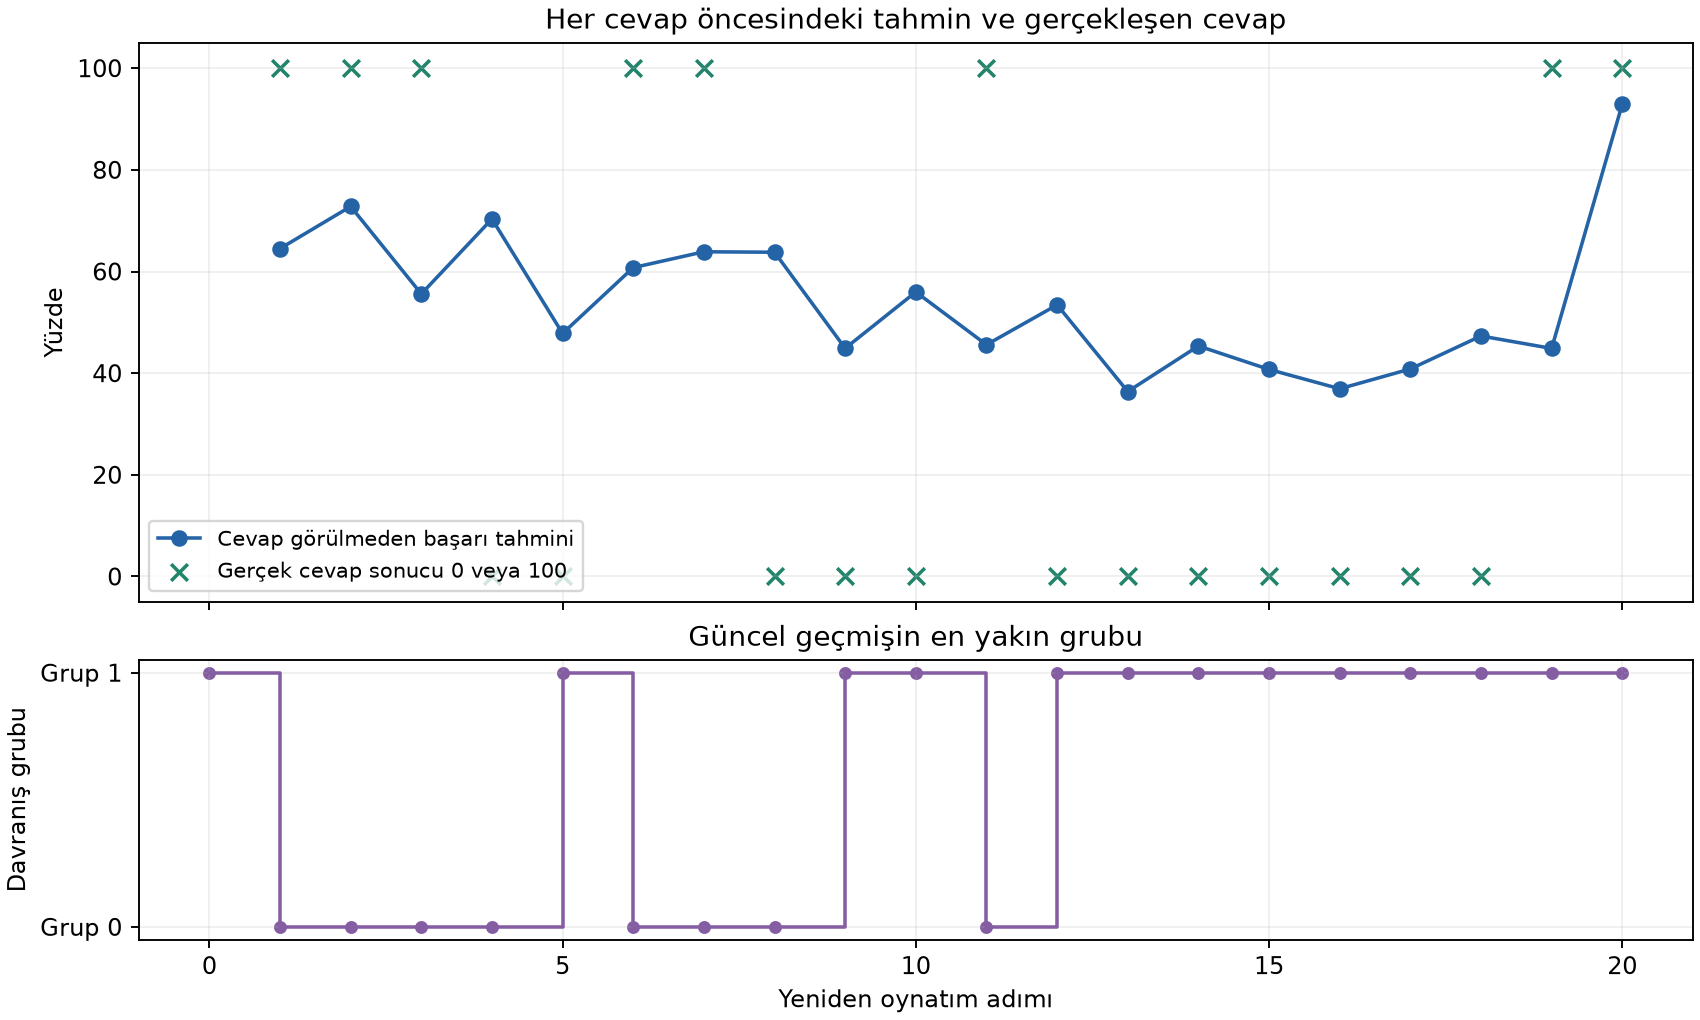

In [2]:
from kt_project.replay import run_replay
display(Code(inspect.getsource(run_replay), language="python"))
states = [session["initial"]] + [event["after"] for event in session["events"]]
events = pd.DataFrame([{
    "Adım": event["step"], "Mevcut soru kimliği": event["original_problem_id"],
    "Cevaptan önce tahmin %": 100*event["predicted_before_response"],
    "Gerçek cevap (1 doğru)": event["observed_correct"],
    "Son 20 cevapta doğru %": 100*event["after"]["observed_recent_correct_ratio"],
    "Cevaptan sonraki grup": event["after"]["behavior"]["cluster"],
} for event in session["events"]])
display(events.round(2))
groups = [state["behavior"]["cluster"] for state in states]
print("Grup geçiş sayısı:", sum(a != b for a, b in zip(groups, groups[1:])))
display(Image(filename=str(ROOT / "outputs/figures/replay_predictions_and_groups.png")))

## Beceri göstergelerinin cevap adımlarındaki değişimi

Mavi çizgi sabit referans sorularındaki tahmindir; kesikli çizgi yakın
dönem gözlenen orandır. Yalnızca bir doğru cevaba dayanan yüzde 100 oran
kesin öğrenme yüzdesi olarak yorumlanmaz. Çizgiler ayrık cevap adımlarını
birleştirir; aralarda sürekli öğrenme ölçümü yapılmamıştır.

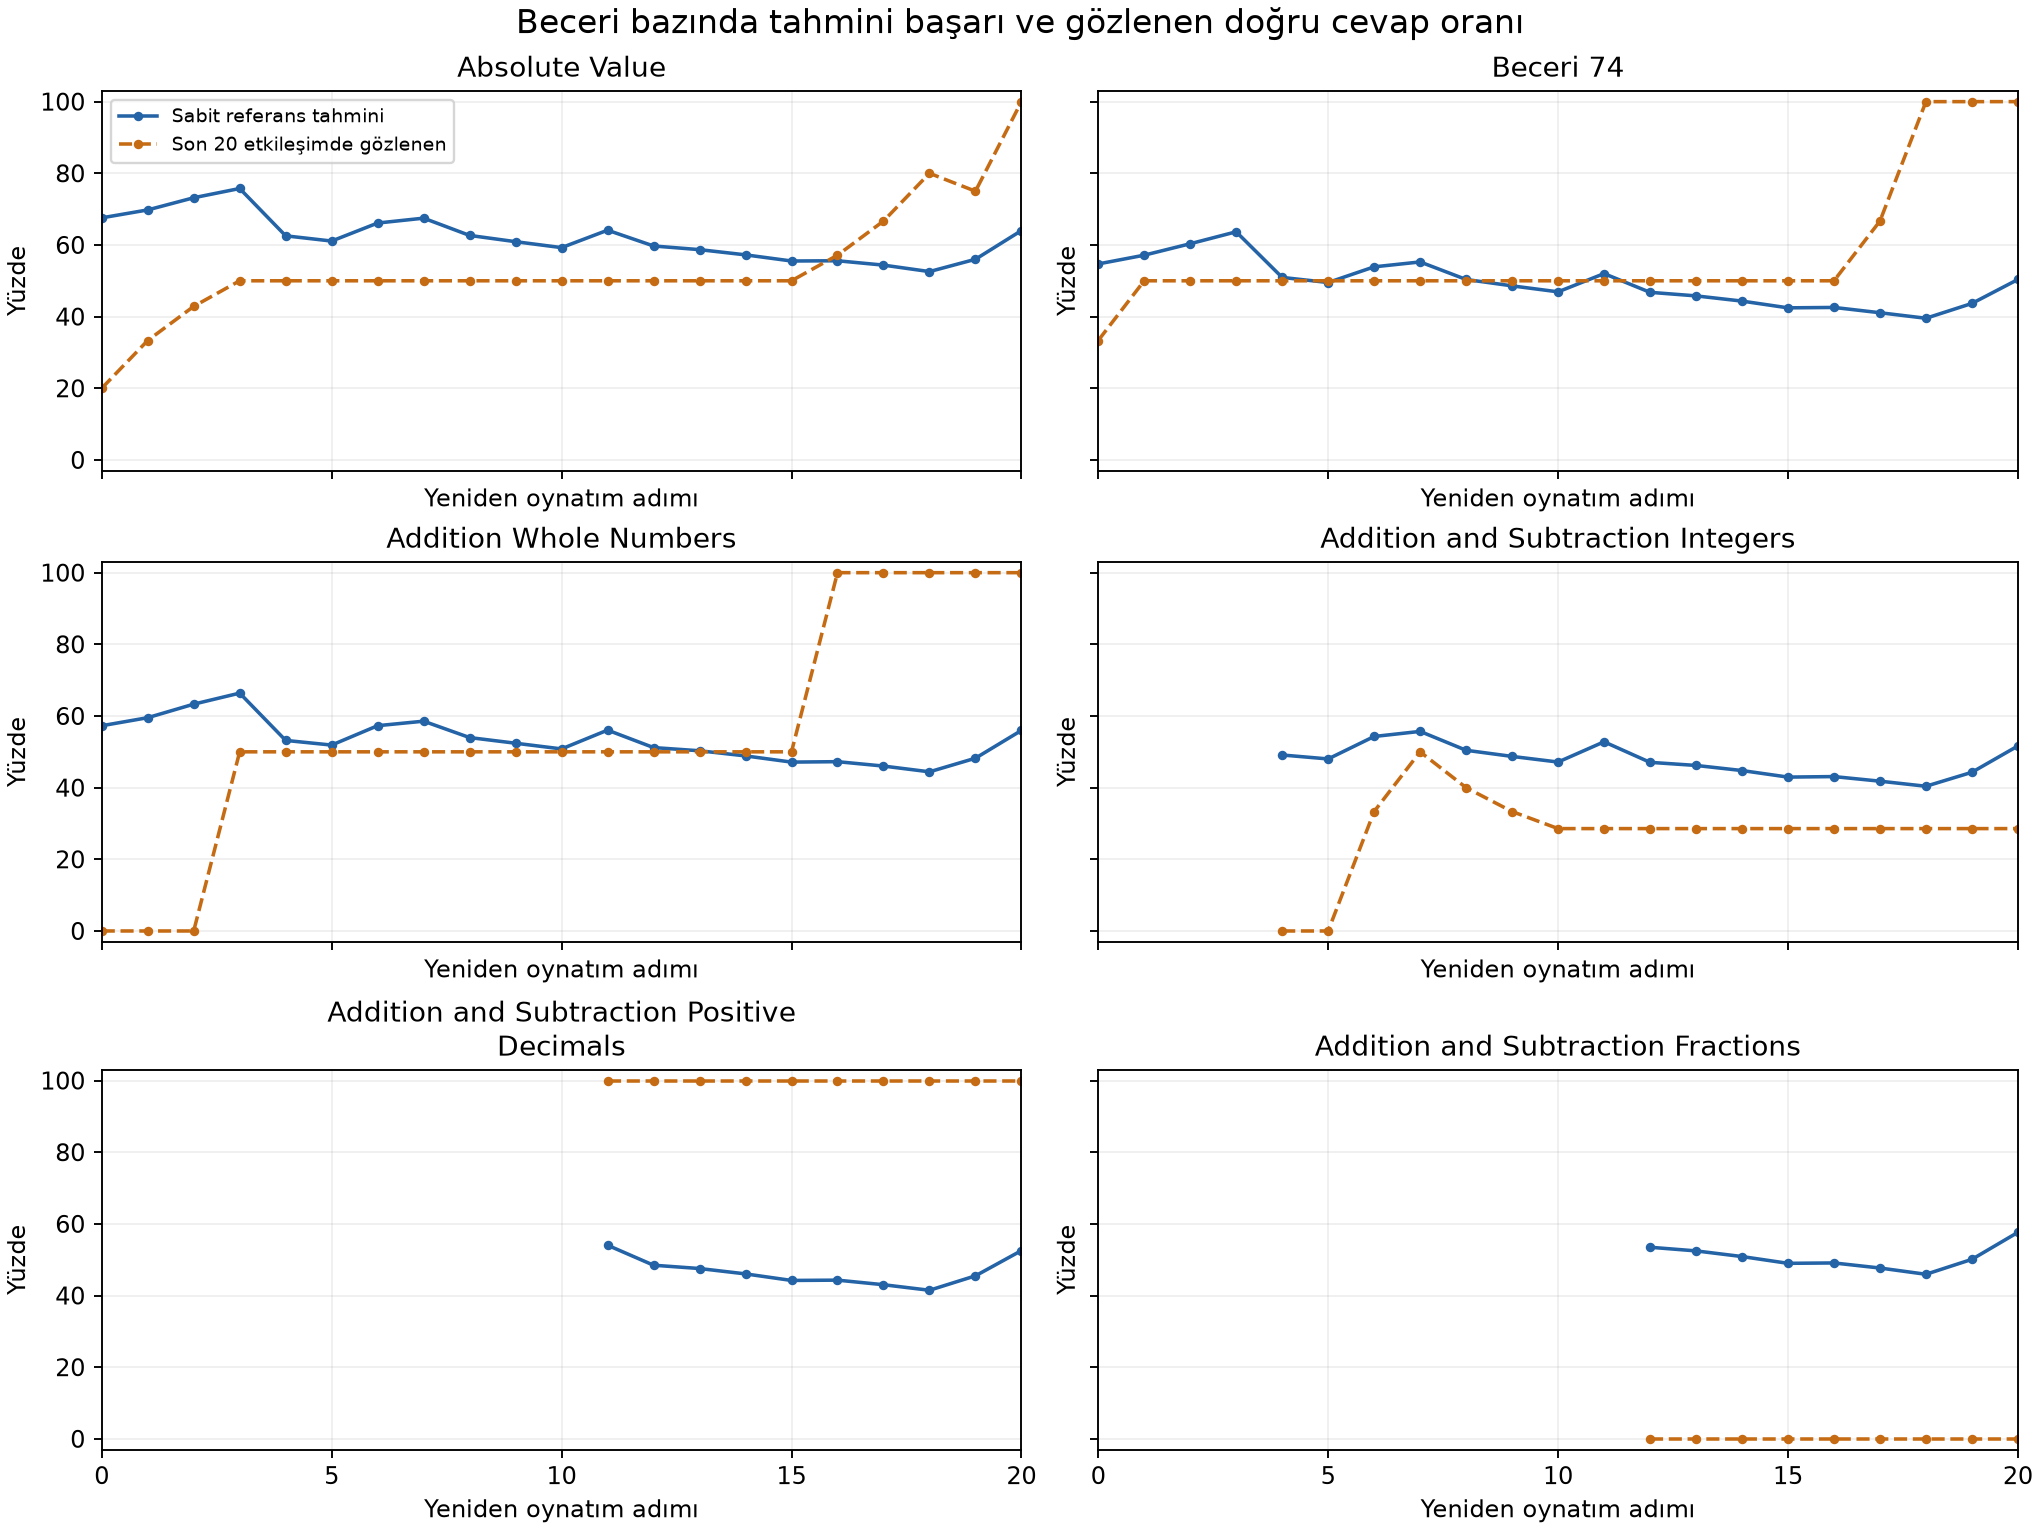

,skill,Beceri,Referans tahmini %,Gözlenen doğru %,Yakın dönem cevap sayısı,Sabit referans soru sayısı
0,57,Absolute Value,64.02,100.00,4,32
1,47,Beceri 74,50.36,100.00,1,32
2,39,Addition Whole Numbers,55.97,100.00,1,32
3,81,Addition and Subtraction Integers,51.64,28.57,7,32
4,82,Addition and Subtraction Positive Decimals,52.54,100.00,1,32
5,84,Addition and Subtraction Fractions,57.64,0.00,7,32


In [3]:
display(Image(filename=str(ROOT / "outputs/figures/replay_skill_progress.png")))
display(pd.DataFrame(states[-1]["skill_scores"]).rename(columns={
    "name": "Beceri", "predicted_success_percent": "Referans tahmini %",
    "observed_correct_percent": "Gözlenen doğru %", "recent_skill_answers": "Yakın dönem cevap sayısı",
    "reference_question_count": "Sabit referans soru sayısı"}).round(2))

## Gerekçeli mevcut soru önerileri

Yakın geçmişte aktif becerilerden referans tahmini en düşük olan seçilir.
Hedef doğru cevap olasılığı normalde yüzde 65, son üç cevap yanlışsa
yüzde 80, son üç cevap doğruysa yüzde 55'tir. Eğitim soruları arasından
bu hedefe yakın ve mümkünse önceden cevaplanmamış bir soru önerilir.
Eşikler açık kurallardır; öğrenilmiş öneri politikası değildir.

Kaynakta soru metni bulunmadığından gerçek soru kimliği gösterilir.
Yeniden oynatımda izleyen kayıt, önerilen soru olmak zorunda değildir;
bu nedenle önerinin öğrenme etkisi burada ölçülmez.

def challenge_probability(recent_correct, config):
    recent = np.asarray(recent_correct)
    if len(recent) >= 3 and np.all(recent[-3:] == 0):
        return config["probability_after_repeated_errors"], "son üç cevap yanlış; daha erişilebilir başarı hedefi"
    if len(recent) >= 3 and np.all(recent[-3:] == 1):
        return config["probability_after_repeated_successes"], "son üç cevap doğru; daha zorlayıcı başarı hedefi"
    return config["recommended_probability"], "orta düzeyde zorlayıcı başarı hedefi"

,Adım,Önerilen mevcut soru,Beceri,Hedef doğru %,Soru tahmini %,Tekrar sorusu
0,0,53749,Beceri 74,65.0,64.78,False
1,1,85283,Beceri 74,65.0,64.96,False
2,2,48464,Beceri 74,65.0,65.05,False
3,3,49350,Beceri 74,55.0,54.79,False
4,4,53709,Beceri 74,65.0,65.05,False
5,5,49299,Beceri 74,65.0,64.87,False
6,6,49310,Beceri 74,65.0,64.96,False
7,7,53769,Beceri 74,65.0,65.05,False
8,8,49292,Beceri 74,65.0,65.05,False
9,9,53753,Beceri 74,65.0,64.78,False


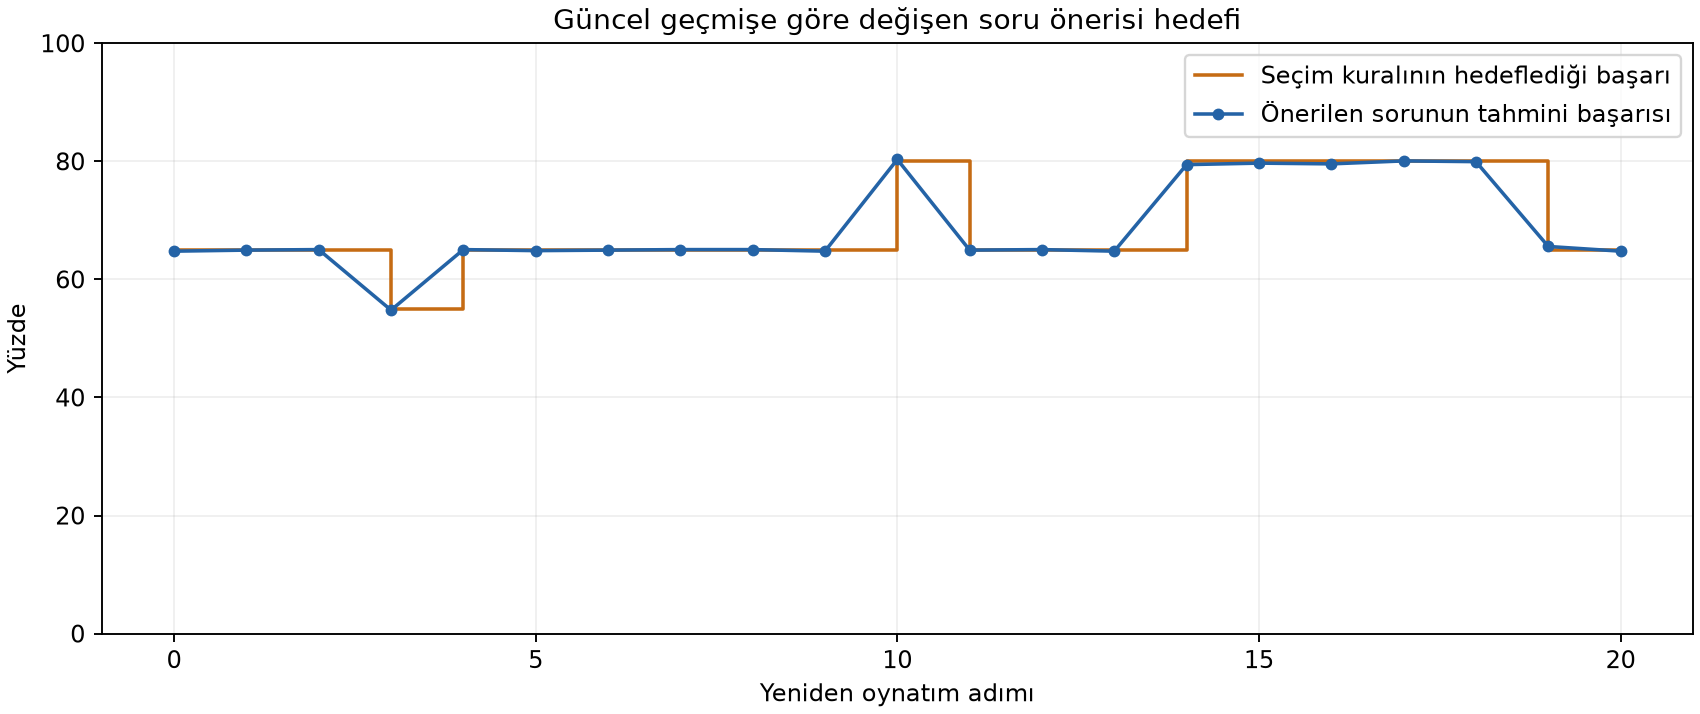

In [4]:
from kt_project.recommendations import challenge_probability
display(Code(inspect.getsource(challenge_probability), language="python"))
recommendations = pd.DataFrame([{
    "Adım": i, "Önerilen mevcut soru": state["recommendation"].get("original_problem_id"),
    "Beceri": state["recommendation"].get("skill_name"),
    "Hedef doğru %": 100*state["recommendation"].get("target_probability", float("nan")),
    "Soru tahmini %": 100*state["recommendation"].get("predicted_probability", float("nan")),
    "Tekrar sorusu": state["recommendation"].get("repeat_question"),
} for i, state in enumerate(states)])
display(recommendations.round(2))
display(Image(filename=str(ROOT / "outputs/figures/replay_recommendation_targets.png")))

## Sunum için bir adımı inceleme

`step_number` değerini 0–20 arasında değiştirip bu hücreyi çalıştırın.
Sıfır başlangıç durumudur. Her seçimde aynı kayıtlı oturumun o andaki
göstergeleri ve öneri gerekçesi gösterilir.

In [5]:
step_number = 10
if not 0 <= step_number < len(states):
    raise ValueError(f"Adım 0 ile {len(states)-1} arasında olmalı.")
selected = states[step_number]
print("Adım:", step_number, "Geçmiş cevap sayısı:", selected["history_count"])
display(pd.DataFrame(selected["skill_scores"]).round(2))
print("Davranış grubu:", selected["behavior"]["cluster"], selected["behavior"]["description"])
print("Öneri:", selected["recommendation"]["reason"])

Adım: 10 Geçmiş cevap sayısı: 15


,skill,name,predicted_success_percent,observed_correct_percent,recent_skill_answers,reference_question_count
0,57,Absolute Value,59.26,50.00,8,32
1,47,Beceri 74,46.91,50.00,4,32
2,39,Addition Whole Numbers,50.81,50.00,2,32
3,81,Addition and Subtraction Integers,47.15,28.57,7,32


Davranış grubu: 1 Doğru cevap oranı görece düşük; yanıt süresi görece kısa
Öneri: Beceri 74: izlenen beceriler arasında referans başarı tahmini en düşük olan beceri; sabit referans başarı tahmini %46.9. son üç cevap yanlış; daha erişilebilir başarı hedefi. Seçilen soruda tahmin %80.3, hedef %80.


## Zaman bilgisinin anlamı ve güvenilirlik denetimi

Kaynakta bu kayıtların gerçek takvim zamanları bulunmuyor. Sıralama gerçek
kaynak sıra kimliğiyle korunur. Gösterim zamanı programın çalıştığı ana
aittir; öğrencinin geçmişte soruyu cevapladığı tarih değildir. Bu oturum
zamana yayılmış gerçek öğrenme kazanımı deneyi olarak sunulmaz.

In [6]:
display(pd.DataFrame([{
    "Adım": event["step"], "Kaynak sıra kimliği": event["source_order_id"],
    "Kaynak takvim zamanı": event["source_timestamp"],
    "Program gösterim zamanı": event["display_timestamp"],
} for event in session["events"]]).iloc[[0, -1]])
display(pd.Series(session["integrity"], name="Oturum kontrolleri"))
run_script("audit_student_tracking.py")
display(pd.Series(read_json("outputs/validation/student_tracking_integrity.json")))

,Adım,Kaynak sıra kimliği,Kaynak takvim zamanı,Program gösterim zamanı
0,1,32772361,None,2026-11-15T14:17:37.897+03:00
19,20,33047323,None,2026-11-15T14:17:38.764+03:00


model_weights_unchanged                      True
behavior_model_unchanged                     True
reference_bank_unchanged                     True
each_prediction_precedes_target_response     True
source_calendar_times_fabricated            False
Name: Oturum kontrolleri, dtype: bool

{"training_only_pattern_snapshots_verified": true, "snapshots_checked": 9598, "selected_clusters": 2, "feature_values_recomputed": true, "scaler_training_statistics_verified": true, "group_selection_verified": true, "real_replay_outcomes_verified": true, "replay_steps": 20, "recommendation_rules_verified": true, "model_and_reference_immutability_verified": true, "source_calendar_timestamps_not_fabricated": true, "main_experiment_source_hashes_unchanged": true}



training_only_pattern_snapshots_verified     True
snapshots_checked                            9598
selected_clusters                               2
feature_values_recomputed                    True
scaler_training_statistics_verified          True
group_selection_verified                     True
real_replay_outcomes_verified                True
replay_steps                                   20
recommendation_rules_verified                True
model_and_reference_immutability_verified    True
source_calendar_timestamps_not_fabricated    True
main_experiment_source_hashes_unchanged      True
dtype: object

In [7]:
result = subprocess.run([sys.executable, "-m", "unittest", "discover", "-s", "tests", "-v"],
                        cwd=ROOT, capture_output=True, text=True,
                        encoding="utf-8", errors="replace")
test_output = result.stdout + result.stderr
(ROOT / "outputs/validation/tracking_test_output.txt").write_text(test_output, encoding="utf-8")
print(test_output)
result.check_returncode()

test_multiple_skills_are_one_event_and_conflicts_are_excluded (test_data_preparation.PreparationTests.test_multiple_skills_are_one_event_and_conflicts_are_excluded) ... ok
test_test_answers_do_not_change_training_difficulty_or_references (test_data_preparation.PreparationTests.test_test_answers_do_not_change_training_difficulty_or_references) ... ok
test_missing_or_duplicated_run_is_rejected (test_experiment_results.ExperimentResultsTests.test_missing_or_duplicated_run_is_rejected) ... ok
test_prototype_selection_is_unchanged_when_test_scores_change (test_experiment_results.ExperimentResultsTests.test_prototype_selection_is_unchanged_when_test_scores_change) ... ok
test_sample_standard_deviation_uses_three_independent_seeds (test_experiment_results.ExperimentResultsTests.test_sample_standard_deviation_uses_three_independent_seeds) ... ok
test_complete_fixture_is_verified (test_experiment_results.SavedExperimentAuditTests.test_complete_fixture_is_verified) ... ok
test_nonfinite_saved_we